# Concept Bottleneck Models for Interpretable ECG Diagnosis — 01: Data & Concepts

## Project overview
Deep learning models reach strong performance on ECG classification, but their reasoning is opaque
and cannot be corrected by a clinician at decision time. This project studies **Concept Bottleneck
Models (CBMs)**, which force predictions to pass through human-interpretable clinical concepts
(ECG form and rhythm findings) before producing a diagnosis.

**Research questions**
1. Can a CBM match the diagnostic performance of an equivalent black-box model on 12-lead ECGs?
2. How much does performance improve when an expert corrects predicted concepts at test time
   (concept interventions), and does the order of intervention matter (random vs. uncertainty-based)?
3. Are the learned concept → diagnosis relationships clinically plausible?

**Data:** PTB-XL v1.0.3 (PhysioNet), 21,799 clinical 12-lead ECGs (10 s, 100 Hz).
Task: multi-label classification of 5 diagnostic superclasses (NORM, MI, STTC, CD, HYP).
Concepts: SCP-ECG form and rhythm statements, excluding those that overlap with diagnostic
statements (to prevent label leakage). Official stratified folds: 1–8 train, 9 validation, 10 test.

## This notebook
1. Load metadata and build task labels and the concept matrix
2. EDA: concept coverage, prevalence and concept → superclass associations
3. Load raw 100 Hz signals and cache arrays for the modelling notebooks

**Outputs** (`/kaggle/working`): `X100.npy`, `labels.npz`, `concepts.csv`, figures.

*Author: Antonio R. Boza León*

## 0. Install dependencies
`wfdb` (PhysioNet WaveForm DataBase) reads the raw ECG records (`.dat` + `.hea`). Requires Internet enabled.

In [1]:
!pip install -q wfdb

## 1. Locate the dataset
Finds PTB-XL v1.0.3 under `/kaggle/input` regardless of the exact mount path and defines the output folder.

In [2]:
import ast
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb

hits = glob.glob("/kaggle/input/**/ptbxl_database.csv", recursive=True)
assert hits, "PTB-XL not found: add it via 'Add Input'"
ROOT = Path(hits[0]).parent
OUT = Path("/kaggle/working")
print("ROOT:", ROOT)
print(sorted(os.listdir(ROOT)))

ROOT: /kaggle/input/datasets/garethwmch/ptb-xl-1-0-3/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
['LICENSE.txt', 'RECORDS', 'SHA256SUMS.txt', 'example_physionet.py', 'ptbxl_database.csv', 'ptbxl_v102_changelog.txt', 'ptbxl_v103_changelog.txt', 'records100', 'records500', 'scp_statements.csv']


## 2. Load metadata
- `ptbxl_database.csv`: one row per ECG with its SCP-ECG statements (`scp_codes`, a dict `{code: likelihood}`) and the official stratified fold (`strat_fold`).
- `scp_statements.csv`: definition of each SCP code and whether it is a **diagnostic**, **form** or **rhythm** statement.

In [3]:
db = pd.read_csv(ROOT / "ptbxl_database.csv", index_col="ecg_id")
db["scp_codes"] = db["scp_codes"].apply(ast.literal_eval)  # str -> dict {code: likelihood}
scp = pd.read_csv(ROOT / "scp_statements.csv", index_col=0)
print("records:", db.shape, "| statements:", scp.shape)
print(scp[["diagnostic", "form", "rhythm"]].sum())

records: (21799, 27) | statements: (71, 12)
diagnostic    44.0
form          19.0
rhythm        12.0
dtype: float64


## 3. Define the concept set
Concepts are the **form** and **rhythm** statements: human-interpretable ECG findings (e.g., ST depression, atrial fibrillation).

**Leakage control:** statements that are both form and diagnostic (`DIG`, `LNGQT`, `NDT`, `NST_`) map directly to the STTC superclass. Keeping them would encode the label inside the bottleneck, so they are excluded.

In [4]:
diag = scp[scp["diagnostic"] == 1]
form = scp[scp["form"] == 1]
rhythm = scp[scp["rhythm"] == 1]

# Statements that are BOTH form/rhythm and diagnostic would leak the label into the bottleneck.
leak = sorted((set(form.index) | set(rhythm.index)) & set(diag.index))
print("Excluded (overlap with diagnostic):", leak)

CONCEPTS = sorted((set(form.index) | set(rhythm.index)) - set(diag.index))
FORM_C = [c for c in CONCEPTS if c in form.index]
RHYTHM_C = [c for c in CONCEPTS if c in rhythm.index]
print(f"{len(CONCEPTS)} concepts | form={len(FORM_C)} rhythm={len(RHYTHM_C)}")

Excluded (overlap with diagnostic): ['DIG', 'LNGQT', 'NDT', 'NST_']
27 concepts | form=15 rhythm=12


## 4. Build task labels and concept matrix
- **Y** (N × 5): multi-label target, the 5 diagnostic superclasses (NORM, MI, STTC, CD, HYP), derived from the diagnostic statements.
- **C** (N × 27): binary concept matrix. A concept is positive if its code is present, regardless of likelihood (rhythm codes such as SR are stored with likelihood 0.0 even when present).

In [5]:
# Presence of a code = positive. Do NOT threshold on likelihood: rhythm codes like SR carry 0.0.
SUPER = ["NORM", "MI", "STTC", "CD", "HYP"]

def to_super(codes):
    return {diag.loc[c, "diagnostic_class"] for c in codes if c in diag.index}

db["superclass"] = db["scp_codes"].apply(to_super)
Y = np.array([[int(s in sc) for s in SUPER] for sc in db["superclass"]], dtype=np.int8)
C = np.array([[int(c in codes) for c in CONCEPTS] for codes in db["scp_codes"]], dtype=np.int8)
has_y = Y.sum(1) > 0

form_idx = [CONCEPTS.index(c) for c in FORM_C]
rhythm_idx = [CONCEPTS.index(c) for c in RHYTHM_C]
has_form = C[:, form_idx].sum(1) > 0
has_rhythm = C[:, rhythm_idx].sum(1) > 0

## 5. EDA: coverage and prevalence
Checks how many records carry each type of annotation, the class balance and the number of positives per concept.

**Key finding:** rhythm statements cover 96.5% of records, but form statements only 33.5%. Absence of a form code is therefore ambiguous (not present vs. not annotated). We treat absence as negative (standard practice for PTB-XL) and discuss the resulting label noise as a limitation. Concepts with fewer than 50 positives are discarded (19 retained).

In [6]:
N = len(db)
print(f"Total records:            {N}")
print(f"With >=1 superclass:      {has_y.sum()} ({has_y.mean():.1%})")
print(f"With >=1 form concept:    {has_form.sum()} ({has_form.mean():.1%})")
print(f"With >=1 rhythm concept:  {has_rhythm.sum()} ({has_rhythm.mean():.1%})")
print(f"Superclass AND form:      {(has_y & has_form).sum()}")

print("\nSuperclass prevalence (records with label):")
print(pd.Series(Y[has_y].mean(0), index=SUPER).round(3))

prev = pd.Series(C[has_y].sum(0), index=CONCEPTS).sort_values(ascending=False)
print("\nConcept positives (records with label):")
print(prev.to_string())

print("\nRecords per fold (9 = val, 10 = test):")
print(db.loc[has_y, "strat_fold"].value_counts().sort_index().to_string())

Total records:            21799
With >=1 superclass:      21388 (98.1%)
With >=1 form concept:    7302 (33.5%)
With >=1 rhythm concept:  21030 (96.5%)
Superclass AND form:      7261

Superclass prevalence (records with label):
NORM    0.445
MI      0.256
STTC    0.245
CD      0.229
HYP     0.124
dtype: float64

Concept positives (records with label):
SR        16734
ABQRS      3310
AFIB       1451
PVC        1128
STD_       1004
VCLVH       873
STACH       818
SARRH       772
SBRAD       635
QWAVE       548
LOWT        438
NT_         423
PAC         397
LPR         340
INVT        294
LVOLT       179
SVARR       151
BIGU         71
HVOLT        62
TAB_         35
STE_         27
AFLT         24
SVTAC        22
TRIGU        20
PACE         10
PRC(S)        9
PSVT          9

Records per fold (9 = val, 10 = test):
strat_fold
1     2139
2     2138
3     2150
4     2130
5     2135
6     2129
7     2134
8     2129
9     2146
10    2158


## 6. Concept → superclass association
Heatmap of P(superclass | concept present) for concepts with ≥50 positives. Used as a **clinical plausibility check** of the concept set (e.g., Q waves → MI, ST depression → STTC, LVH voltage criteria → HYP).

Rows do not sum to 1 (multi-label) and values show association, not causation. Only one concept (LPR) points to CD, because bundle branch blocks are diagnostic statements: we expect the CBM to lose most performance on **CD**, then **STTC** (hypothesis stated before training).

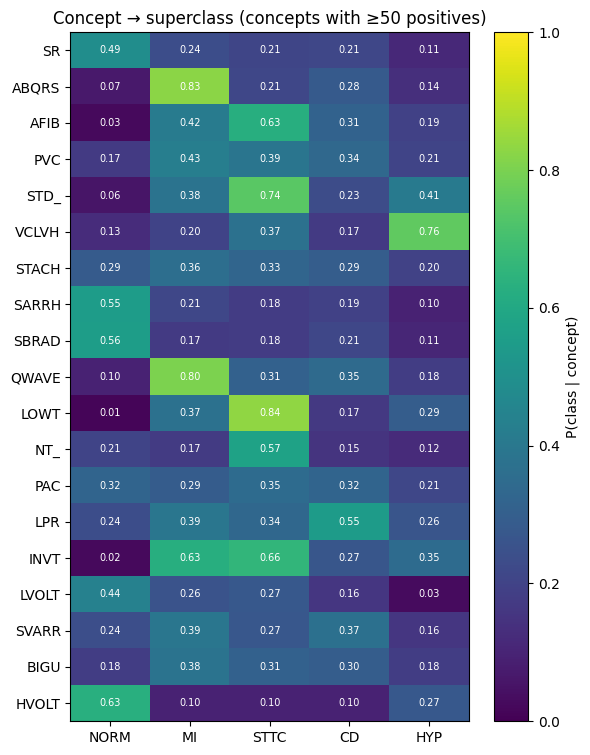

In [7]:
MIN_POS = 50  # concepts with fewer positives can't be learned/evaluated reliably
keep = prev[prev >= MIN_POS].index.tolist()
Yl, Cl = Y[has_y], C[has_y]
cond = pd.DataFrame(
    {c: Yl[Cl[:, CONCEPTS.index(c)] == 1].mean(0) for c in keep}, index=SUPER
).T

fig, ax = plt.subplots(figsize=(6, 0.35 * len(keep) + 1))
im = ax.imshow(cond.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(SUPER)), SUPER)
ax.set_yticks(range(len(keep)), keep)
for i in range(len(keep)):
    for j in range(len(SUPER)):
        ax.text(j, i, f"{cond.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, label="P(class | concept)")
ax.set_title(f"Concept → superclass (concepts with ≥{MIN_POS} positives)")
plt.tight_layout()
plt.savefig(OUT / "concept_class_heatmap.png", dpi=150)
plt.show()

## 7. Load raw signals and cache arrays
Reads all 21,799 records at 100 Hz (10 s × 12 leads) in parallel and saves them as NumPy arrays, so the modelling notebooks load the data in seconds.

Outputs: `X100.npy` (21799 × 1000 × 12), `labels.npz` (Y, C, masks, folds, IDs), `concepts.csv`.

In [8]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def read_rec(f):
    return wfdb.rdsamp(str(ROOT / f))[0].astype(np.float32)

with ThreadPoolExecutor(max_workers=16) as ex:
    X = np.stack(list(tqdm(ex.map(read_rec, db["filename_lr"]), total=len(db))))

print("X:", X.shape)  # expected (21799, 1000, 12)
np.save(OUT / "X100.npy", X)
np.savez(
    OUT / "labels.npz",
    Y=Y, C=C, has_y=has_y, has_form=has_form,
    fold=db["strat_fold"].values, ecg_id=db.index.values,
)
pd.Series(CONCEPTS, name="concept").to_csv(OUT / "concepts.csv", index=False)

  0%|          | 0/21799 [00:00<?, ?it/s]

X: (21799, 1000, 12)


## 8. Sanity check
Lead II of one single-label example per superclass, to verify the signals were loaded correctly. Baseline wander is visible in some records. We follow the PTB-XL benchmark (per-lead standardization only, no filtering) to keep results comparable.

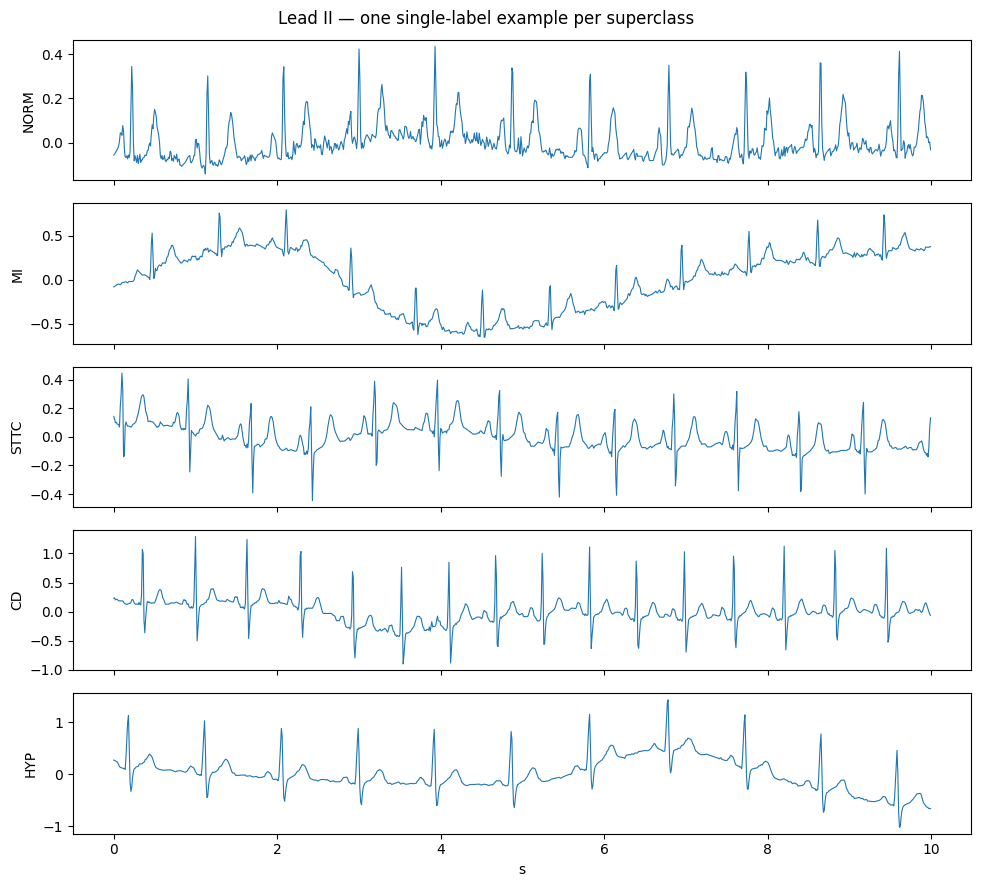

In [9]:
LEAD_II = 1
fig, axes = plt.subplots(len(SUPER), 1, figsize=(10, 9), sharex=True)
t = np.arange(1000) / 100
for ax, k in zip(axes, range(len(SUPER))):
    i = np.where((Y[:, k] == 1) & (Y.sum(1) == 1))[0][0]  # record with only this class
    ax.plot(t, X[i, :, LEAD_II], lw=0.8)
    ax.set_ylabel(SUPER[k])
axes[-1].set_xlabel("s")
plt.suptitle("Lead II — one single-label example per superclass")
plt.tight_layout()
plt.savefig(OUT / "examples_lead2.png", dpi=150)
plt.show()